In [ ]:
import os
import warnings
from dataclasses import replace
from pathlib import Path
from tempfile import TemporaryDirectory

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np
import optuna

import pyrite

optuna.logging.set_verbosity(optuna.logging.WARNING)
_ = pyrite.fetch_tables()
tables_ready = True
checkpoint_directory = TemporaryDirectory(prefix="pyrite-optimization-tutorial-")

# Optimizing an X-ray source

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/11-optimizing-xray-source.py)

Search graphite tilt and thickness for PXR/CBS yield in **820–900 eV**,
subject to a **50 nm** thickness limit. Then evaluate the selected design
with independent seeds. The optimization API is experimental.

If run locally rather than on Molab, first install `Optuna` alongside `pyrite` with

```bash
uv tool install "pyrite-mc[optimization]"
```

In [ ]:
from pyrite import Scene
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.optimization import (
    Constraint,
    FixedWindowYield,
    Integer,
    Objective,
    OptimizationStudy,
    OptunaOptimizer,
    ParameterSpace,
    PyriteEvaluator,
)
from pyrite.results import records

search_numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=16, brem_electrons=16),
    transport_core="per-electron",
    energy_bins=EnergyBins(cxr=np.linspace(750, 1_000, 126), brem=np.array([750.0, 1_000.0])),
    cxr_reflections=CxrReflections(n_families=1),
)
base = Scene(
    Beam(energy_keV=30, transverse=PointSpot(), longitudinal=PointBunch()),
    Slab(
        "hopg",
        thickness_ang=500,
        tilt_deg=45,
        tilt_azim_deg=180,
        footprint=Footprint(5, 5),
        mosaic=False,
    ),
    Detector(observation_angle_deg=90),
    physics=Physics(
        brem_source=None,
        inelastic_model="continuous",
        radiative_model="uncoupled",
        bremsstrahlung_model="eedl",
    ),
    numerics=search_numerics,
)
score = FixedWindowYield(820, 900)
definition = OptimizationStudy(
    base,
    ParameterSpace(
        {
            "target.tilt_deg": Integer(41, 49, step=2),
            "target.thickness_ang": Integer(250, 750, step=250),
        }
    ),
    (Objective(score.name, "maximize", score.units),),
    (Constraint("thickness_ang", "<=", 500, "angstrom"),),
)

In [ ]:
def candidate_metrics(store):
    return {**score(store), "thickness_ang": records(store)[0]["case"]["thickness_ang"]}

In [ ]:
assert tables_ready
run_options = {
    "checkpoint_path": str(Path(checkpoint_directory.name) / "search.h5"),
    "max_workers": 0,
    "cache_read": False,
    "cache_write": False,
}
evaluator = PyriteEvaluator(candidate_metrics, base_seed=21, run_options=run_options)
with warnings.catch_warnings(action="ignore", category=optuna.exceptions.ExperimentalWarning):
    optimizer = OptunaOptimizer(
        definition.parameters,
        definition.objectives,
        constraints=definition.constraints,
        seed=21,
    )
with mo.capture_stdout():
    search_result = definition.run(evaluator, optimizer, max_trials=12)
assert len(search_result.trials) == 12
assert all(_trial.state.value != "failed" for _trial in search_result.trials)
finalist = search_result.best_trial
assert finalist is not None

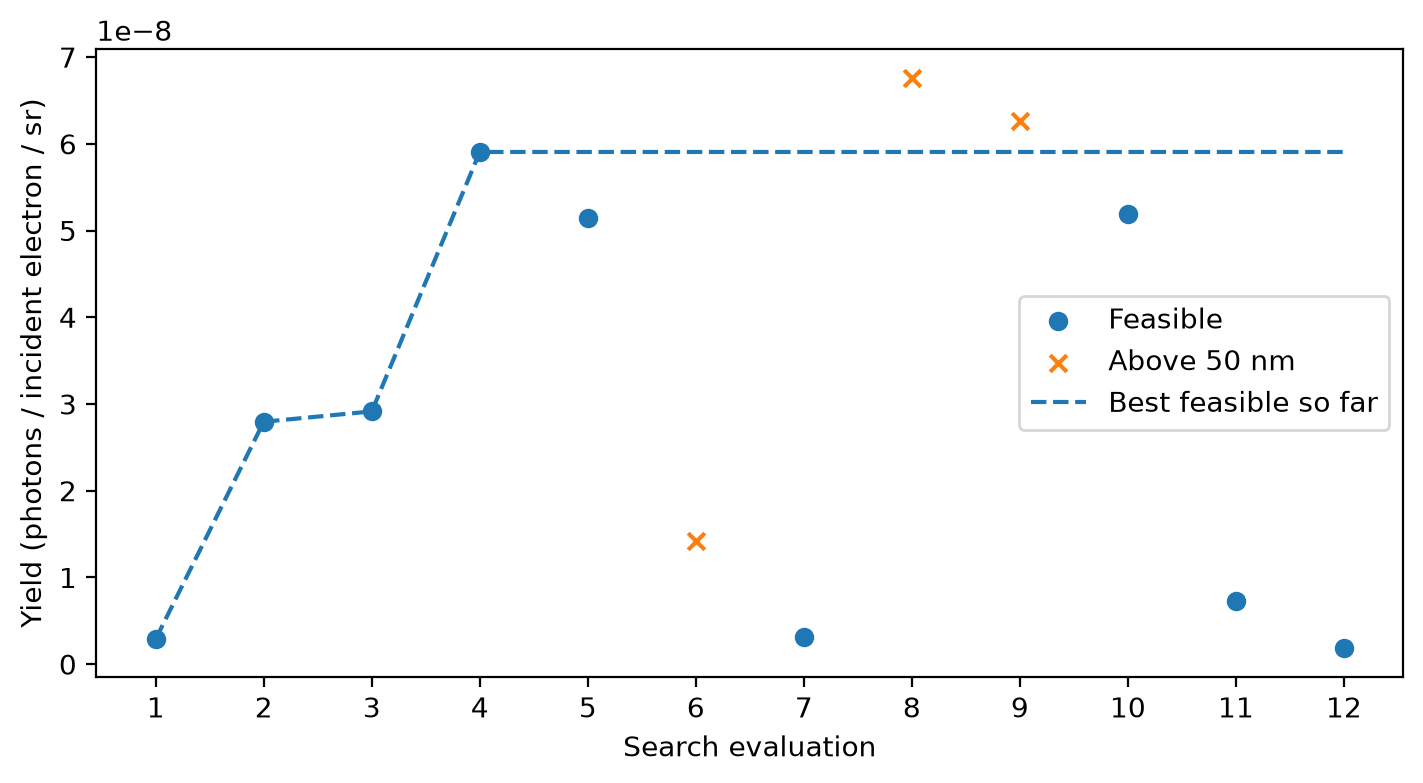

In [ ]:
fig_search, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
_trials = search_result.trials
_numbers = np.array([_trial.number + 1 for _trial in _trials])
_yields = np.array([_trial.objectives[score.name] for _trial in _trials])
_feasible = np.array([_trial.state.value == "completed" for _trial in _trials])
_ax.scatter(_numbers[_feasible], _yields[_feasible], label="Feasible")
_ax.scatter(_numbers[~_feasible], _yields[~_feasible], marker="x", label="Above 50 nm")
_best = np.maximum.accumulate(np.where(_feasible, _yields, -np.inf))
_best[_best == -np.inf] = np.nan
_ax.plot(_numbers, _best, "--", label="Best feasible so far")
_ax.set(
    xlabel="Search evaluation",
    ylabel="Yield (photons / incident electron / sr)",
    xticks=_numbers,
)
_ax.legend()
fig_search  # noqa: B018

In [ ]:
assert tables_ready
validation_numerics = Numerics(
    transport_core="per-electron",
    cxr_reflections=search_numerics.cxr_reflections,
    sampling=FixedSampling(cxr_electrons=128, brem_electrons=128),
    energy_bins=EnergyBins(cxr=np.linspace(750, 1_000, 251), brem=np.array([750.0, 1_000.0])),
)
validation_scene = replace(
    definition.scene(finalist.parameters),
    numerics=validation_numerics,
    physics=base.physics,
)
validation_evaluator = PyriteEvaluator(
    candidate_metrics,
    base_seed=1_001,
    run_options={
        **run_options,
        "checkpoint_path": run_options["checkpoint_path"].replace("search.h5", "validation.h5"),
    },
)
with mo.capture_stdout():
    independent_yields = np.array(
        [
            validation_evaluator(validation_scene, _replicate)[definition.objectives[0].name]
            for _replicate in range(3)
        ]
    )
assert np.isfinite(independent_yields).all() and np.all(independent_yields >= 0)

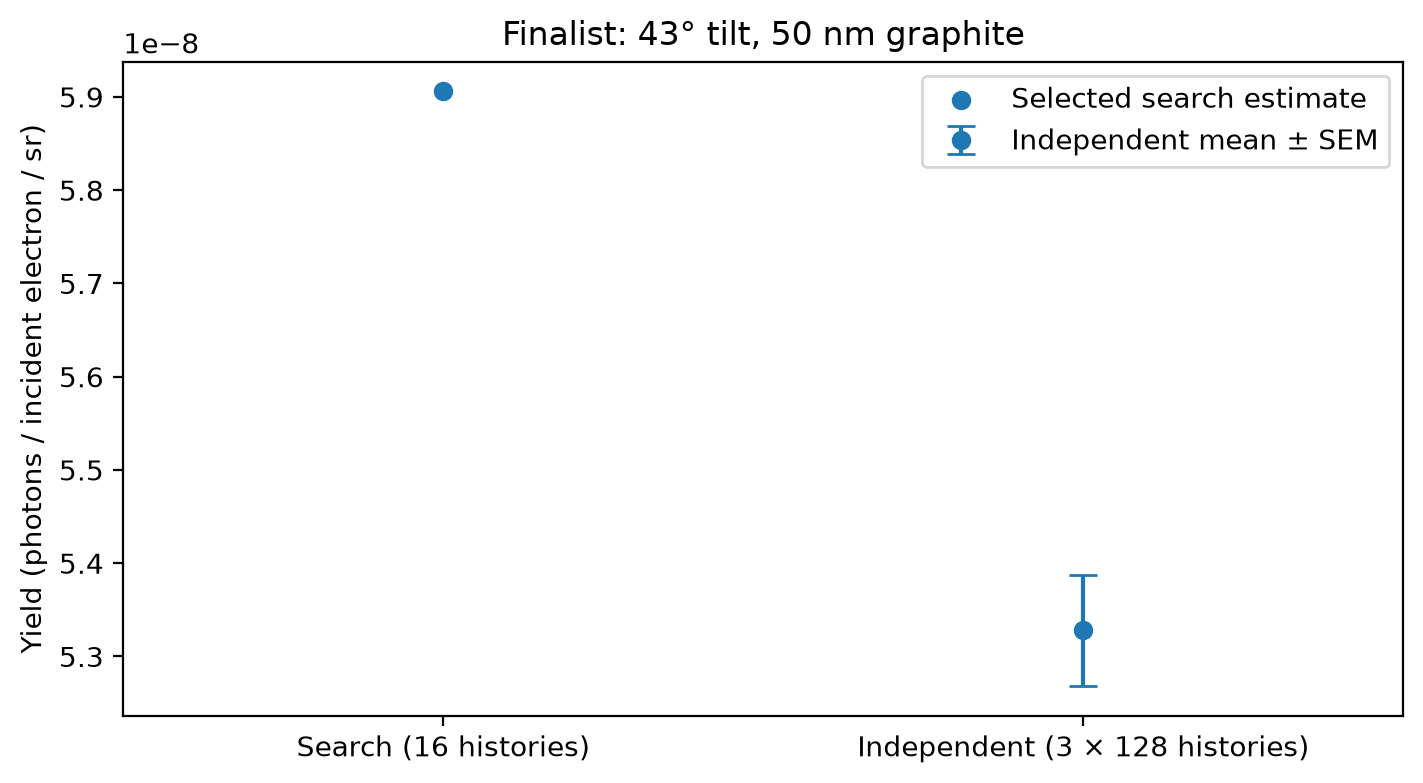

In [ ]:
fig_validation, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
_ax.scatter(0, finalist.objectives[score.name], label="Selected search estimate")
_ax.errorbar(
    1,
    independent_yields.mean(),
    yerr=independent_yields.std(ddof=1) / np.sqrt(3),
    fmt="o",
    capsize=5,
    label="Independent mean ± SEM",
)
_ax.set(
    xticks=(0, 1),
    xticklabels=("Search (16 histories)", "Independent (3 × 128 histories)"),
    ylabel="Yield (photons / incident electron / sr)",
    xlim=(-0.5, 1.5),
    title=f"Finalist: {finalist.parameters['target.tilt_deg']:g}° tilt, "
    f"{finalist.parameters['target.thickness_ang'] / 10:g} nm graphite",
)
_ax.legend()
fig_validation  # noqa: B018

The objective integrates the incoherent PXR/CBS source density at **90°**,
before detector response or angular acceptance. The physical beam energy
and material model stay fixed while the optimizer selects geometry.

Twelve search evaluations use 16 histories per population and seeds 21–32;
the first ten Optuna proposals are startup samples. The finalist uses
three new seeds, 1,001–1,003, and a finer **1 eV** grid instead of **2 eV**.
Its error bar describes sampling only, not grid or model uncertainty.

Try increasing the search budget or tightening the thickness constraint.
A selected noisy maximum does not establish a global optimum.

## Continue learning

See the [optimization study reference](../../reference/optimization-studies.md)
for parameter, constraint and resume contracts; the
[optimization how-to](../../guides/optimization-studies.md) runs a larger comparison.
[Fixed-window integral evidence](../../validation/radiation-physics/optimization-fixed-window-yield.md)
checks the source-yield objective.

{download}`Download canonical Marimo notebook <../11-optimizing-xray-source.py>`